config.json:   0%|          | 0.00/4.61k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  982MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/445 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: nlpconnect/vit-gpt2-image-captioning
Key                                                       | Status     |  | 
----------------------------------------------------------+------------+--+-
decoder.transformer.h.{0...11}.attn.masked_bias           | UNEXPECTED |  | 
decoder.transformer.h.{0...11}.crossattention.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/120 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Model loaded successfully!
Device: cpu


Saving images.jpg to images.jpg
Image loaded: images.jpg


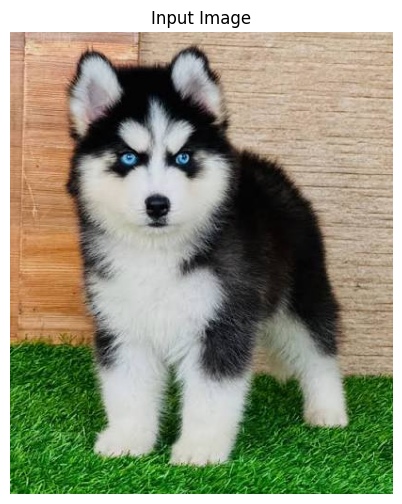

[transformers] We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.
You may ignore this warning if your `pad_token_id` (50256) is identical to the `bos_token_id` (50256), `eos_token_id` (50256), or the `sep_token_id` (None), and your input is not padded.


Generated Caption: a black and white dog sitting in a grassy field 


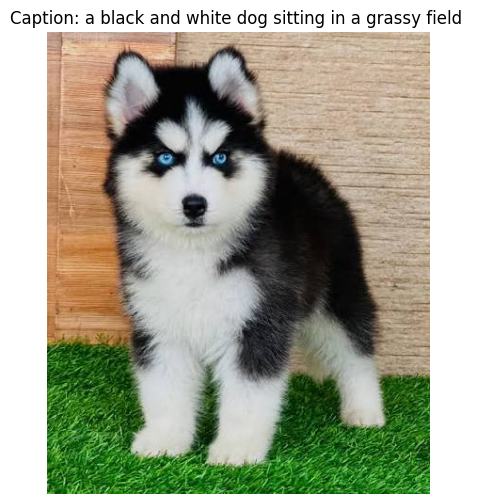

In [ ]:
# ==========================================
# Exp-7: Image Captioning using CNN-RNN Architecture
# ==========================================

# Step 1: Import Required Libraries

import torch
from transformers import VisionEncoderDecoderModel, ViTImageProcessor, AutoTokenizer
from PIL import Image
import matplotlib.pyplot as plt
from transformers.utils import hub

# Set download timeout
hub.HUGGINGFACE_HUB_HTTP_TIMEOUT = 60


# Step 2: Load Pre-trained Image Captioning Model

model_name = "nlpconnect/vit-gpt2-image-captioning"

model = VisionEncoderDecoderModel.from_pretrained(model_name)
processor = ViTImageProcessor.from_pretrained(model_name)
tokenizer = AutoTokenizer.from_pretrained(model_name)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

print("Model loaded successfully!")
print("Device:", device)


# Step 3: Define Caption Generation Function

def generate_caption(image_path, max_length=30, num_beams=4):

    image = Image.open(image_path).convert("RGB")

    pixel_values = processor(
        images=image,
        return_tensors="pt"
    ).pixel_values.to(device)

    with torch.no_grad():
        output_ids = model.generate(
            pixel_values,
            max_length=max_length,
            num_beams=num_beams,
            early_stopping=True
        )

    caption = tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    return caption


# Step 4: Upload an Image

from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Image loaded:", image_path)


# Step 5: Display the Input Image

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Input Image")
plt.show()


# Step 6: Generate Image Caption

caption = generate_caption(
    image_path,
    max_length=30,
    num_beams=4
)

print("Generated Caption:", caption)


# Step 7: Display Image with Generated Caption

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Caption: " + caption)
plt.show()